# QBO zonal wind

## Purpose

Evaluate the QBO zonal-wind evolution of the experiments against ERA-Interim and ERA5.

## Inputs

Model: the 2012-2013 AMIP hindcasts under `INPUT_DATA_ROOT/<case>/post/atm/180x360_aave` (experiments and initial states in `configs/hind_experiment_config.py`). Monthly CMIP-named `ua` (`cmip_ts/monthly`, 19 pressure levels). References: ERA5 and ERA-Interim monthly pressure-level `ua` (E3SM Diags time series under `OBSERVATION_ROOT`; 0.25 and 0.75 degree, read lazily and subset to the model levels and 5S-5N before computing).

## Method

5S-5N cos-lat weighted zonal mean on the model levels (hPa). Amplitudes: half peak-to-peak, RMS, and detrended RMS over the record. Spectral amplitudes need >= 8 years and are not computed for 2012-2013. Scores: RMSE/PCC of the sections, averaged over both reanalyses and against `REFERENCE` alone, with a 95% moving-block bootstrap CI (overlapping `BLOCK_LEN`-month blocks; with 24 months this CI is rough). RMSE/PCC over the record mix the initialized memory with the model's own QBO, so memory and timing are scored separately against the mean of both reanalyses:

* `memory_months`: lead months before the profile correlation (10-100 hPa) with the reference stays below `MEMORY_THRESHOLD` for two months;
* westerly/easterly onset month at each level, following the descending shear zone from 10 hPa, and its error;
* descent rate of the westerly zone over 10-50 hPa (km/month, scale height 7 km) and its error.

Attribution (`util/hind_factorial.py`): each score is fitted as μ + atm + lnd over the 8 single runs; the interaction residual is the noise floor setting each effect's 95% interval. Onsets that do not occur within the record are NaN (CTRL and DARTBA at 30-50 hPa), so effects against the piC atmosphere are then not estimable.

## Outputs

`data/hind_atm_eval/qbo/qbo_<SOURCE>_ua_<period>.nc` (also read by notebooks 02 and 03), `qbo_ua_skill_<REFS>.csv`, `qbo_ua_timing.csv`, `qbo_ua_effects.csv`; figures in `figure/hind_atm_eval/qbo/`:

1. Time-pressure sections of the reference and all sources, RMSE/PCC vs the reference annotated.
2. Source − reference differences.
3. RMS amplitude profiles.
4. RMSE/PCC skill bars, averaged over both reanalyses (their own disagreement drawn as a floor) and vs one reference.
5. Persistence of the initial vertical profile and correlation with the reference vs lead month.
6. Westerly onset by level and U at 30/50 hPa vs lead month.
7. Factorial scorecard of RMSE, PCC, memory and timing.

## 1. Libraries

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import xarray as xr
from IPython.display import display

## 2. User setup

Paths and run options. Edit this cell for normal changes; it holds plain values only, so `papermill -p` overrides work.

In [2]:
INPUT_DATA_ROOT = Path("/global/cfs/cdirs/m4849/zhan391/eam_hindcast")
WORK_DIR = Path("/global/cfs/cdirs/m4849/zhan391/work_package/e3sm_dart_analysis")
DIAGNOSTIC_OUTPUT_ROOT = Path("/global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026")
OBSERVATION_ROOT = Path("/global/cfs/cdirs/e3sm/zhan391/data")  # reference-data archive
WORKFLOW_NAME = "hind_atm_eval"

EXPERIMENTS = ("CTRL", "DARTOP", "ERA5OP", "ERA5DL", "ERA5BL", "DARTBL", "DARTBA", "DARTAE")
REFERENCES = ("ERAI", "ERA5")  # sections for both; skill averaged over them
REFERENCE = "ERAI"             # sections, differences and single-reference skill against this one
OTHER_REANALYSIS = "ERA5"      # also drawn as a source
LAT_BAND = (-5.0, 5.0)
BLOCK_LEN = 6                  # months per bootstrap block
N_BOOT = 500
MEMORY_THRESHOLD = 0.5       # profile correlation below which the initial QBO phase is lost
TIMING_LEVELS = (10.0, 20.0, 30.0, 50.0, 70.0)  # hPa
FORCE_COMPUTE = False
FONT_SCALE = 14
SHOW = True
FIGURE_DPI = 300
USE_DISTRIBUTED = False  # True: local dask.distributed cluster; worker processes read files in parallel
DASK_WORKERS = 8         # threads (threaded scheduler) or worker processes (distributed); bounds memory

## 3. Paths and modules

In [3]:
repo = WORK_DIR.resolve()
if str(repo / "diagnostic") not in sys.path:
    sys.path.insert(0, str(repo / "diagnostic"))
from configs.output_paths import workflow_output_dirs
from util.dask_helpers import compute_all, configure_dask

client = configure_dask(use_distributed=USE_DISTRIBUTED, n_workers=DASK_WORKERS, n_threads=DASK_WORKERS)
data_dir, figure_dir = workflow_output_dirs(WORKFLOW_NAME, 'qbo', output_root=DIAGNOSTIC_OUTPUT_ROOT)
ROOTS = dict(observation_root=OBSERVATION_ROOT)
print(f"[DATA] {data_dir}\n[FIGURE] {figure_dir}")

def save(fig, name):
    path = figure_dir / name
    fig.savefig(path, dpi=FIGURE_DPI, bbox_inches="tight")
    print(f"[FIGURE] {path}")
    if not SHOW:
        plt.close(fig)

[DATA] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo
[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo


## 4. Read input

Saved diagnostics are reused: fields are opened lazily only for the sources whose output file is missing (all of them with `FORCE_COMPUTE`), and loaded in the Derive step.

In [4]:
from configs.hind_experiment_config import PERIOD
from util.qbo_diagnostics import open_qbo_input, qbo_section_path

VARIABLE = "ua"
SOURCES = (*REFERENCES, *EXPERIMENTS)
paths = {s: qbo_section_path(data_dir, s, VARIABLE) for s in SOURCES}
inputs = {s: open_qbo_input(s, VARIABLE, data_root=INPUT_DATA_ROOT, **ROOTS)
          for s in SOURCES if FORCE_COMPUTE or not paths[s].exists()}
print(f"[READ] {', '.join(inputs) or 'nothing: every section is saved'}")

[READ] nothing: every section is saved


## 5. Derive

Equatorial time-height section and amplitude profiles per source. The expensive reductions of every source are computed together in one Dask graph (`compute_all`), so reads and reductions run in parallel; the rest works on the loaded results.

In [5]:
from util.qbo_diagnostics import QboAnalyzer, QboConfig

analyzer = QboAnalyzer(QboConfig.for_variable(VARIABLE, lat_band=LAT_BAND))
reduced = compute_all({s: analyzer.reduce(da) for s, da in inputs.items()})
derived = {s: analyzer.compute_metrics(f"{s}_{VARIABLE}_{PERIOD}", da).assign_attrs(source=s)
           for s, da in reduced.items()}

## 6. Save

Write the newly derived files, then reload every source from disk so the steps below use the same data as a rerun that reuses the files. Check: RMS amplitude at 30 hPa per source.

In [6]:
for s, ds in derived.items():
    ds.to_netcdf(paths[s])
    print(f"[WRITE] {paths[s]}")
sections = {s: xr.load_dataset(p) for s, p in paths.items()}
display(pd.Series({s: float(ds.amp_rms.sel(plev=30)) for s, ds in sections.items()},
                  name="amp_rms_30hPa").round(2))

Warning 3: Cannot find header.dxf (GDAL_DATA is not defined)
ERROR 1: PROJ: proj_create_from_database: Cannot find proj.db


ERAI      18.97
ERA5      19.06
CTRL      12.83
DARTOP    18.41
ERA5OP    17.71
ERA5DL    17.54
ERA5BL    19.43
DARTBL    18.07
DARTBA    14.96
DARTAE    19.20
Name: amp_rms_30hPa, dtype: float64

## 7. Scores

RMSE/PCC of every experiment, averaged over `REFERENCES` and against `REFERENCE`; memory and phase timing against the mean of `REFERENCES`; factorial effects of the initial states on each score.

In [7]:
from util.hind_factorial import factorial_effects
from util.qbo_plotting import QboPlotParameter, QboPlotter, qbo_timing_table

plotter = QboPlotter(QboPlotParameter.for_variable(VARIABLE), data_dir)
skill = {}
for refs in (list(REFERENCES), [REFERENCE]):
    tag = "_".join(refs)
    skill[tag] = plotter.skill_table(refs, EXPERIMENTS, n_boot=N_BOOT, block_len=BLOCK_LEN)
    skill[tag].to_csv(data_dir / f"qbo_ua_skill_{tag}.csv", index=False)
    print(f"[WRITE] {data_dir / f'qbo_ua_skill_{tag}.csv'}")
    display(skill[tag].round(2))

timing = qbo_timing_table(data_dir, REFERENCES, EXPERIMENTS, levels_hpa=TIMING_LEVELS,
                          memory_threshold=MEMORY_THRESHOLD)
timing.to_csv(data_dir / "qbo_ua_timing.csv")
print(f"[WRITE] {data_dir / 'qbo_ua_timing.csv'}")
display(timing[["memory_months", "W_onset_10", "W_onset_30", "W_onset_50", "W_onset_70",
                "descent_km_per_month"]].round(1))

SCORE_COLUMNS = {"rmse": ("RMSE (m/s)", False), "pcc": ("PCC", True), "memory_months": ("Memory (months)", True),
                 "abs_W_onset_err_30": ("|W onset error| 30 hPa (months)", False),
                 "abs_W_onset_err_50": ("|W onset error| 50 hPa (months)", False),
                 "descent_err": ("Descent-rate error (km/month)", False)}
scores = pd.concat([skill["_".join(REFERENCES)].set_index("source")[["rmse", "pcc"]],
                    timing.loc[list(EXPERIMENTS)]], axis=1)[list(SCORE_COLUMNS)].astype(float)
effects = factorial_effects(scores)
effects.to_csv(data_dir / "qbo_ua_effects.csv", index=False)
print(f"[WRITE] {data_dir / 'qbo_ua_effects.csv'}")
display(effects.pivot_table(index="metric", columns="effect", values="estimate", sort=False).round(2))

[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/qbo_ua_skill_ERAI_ERA5.csv


,source,rmse,pcc,rmse_lo,rmse_hi,pcc_lo,pcc_hi,rmse_ref_halfrange,pcc_ref_halfrange
0,CTRL,16.19,-0.33,15.78,17.56,-0.60,-0.20,0.14,0.02
1,DARTOP,12.71,0.30,11.50,14.23,0.05,0.45,0.07,0.01
2,ERA5OP,14.48,0.15,13.38,15.91,-0.08,0.30,0.05,0.02
3,ERA5DL,14.88,0.14,13.86,16.55,-0.10,0.25,0.09,0.01
4,ERA5BL,14.10,0.27,12.92,15.64,0.06,0.39,0.11,0.00
5,DARTBL,12.94,0.29,11.83,14.30,0.08,0.44,0.15,0.00
6,DARTBA,16.39,-0.34,15.88,17.94,-0.62,-0.22,0.11,0.03
7,DARTAE,13.83,0.24,12.76,15.36,-0.00,0.40,0.03,0.01


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/qbo_ua_skill_ERAI.csv


,source,rmse,pcc,rmse_lo,rmse_hi,pcc_lo,pcc_hi,rmse_ref_halfrange,pcc_ref_halfrange
0,CTRL,16.33,-0.31,15.90,17.64,-0.58,-0.16,0.0,0.0
1,DARTOP,12.78,0.31,11.53,14.23,0.06,0.45,0.0,0.0
2,ERA5OP,14.52,0.17,13.43,15.89,-0.07,0.31,0.0,0.0
3,ERA5DL,14.97,0.15,13.97,16.59,-0.09,0.26,0.0,0.0
4,ERA5BL,14.21,0.27,12.99,15.66,0.07,0.39,0.0,0.0
5,DARTBL,13.09,0.29,11.99,14.32,0.09,0.44,0.0,0.0
6,DARTBA,16.50,-0.32,15.92,18.03,-0.61,-0.16,0.0,0.0
7,DARTAE,13.87,0.26,12.72,15.35,0.01,0.40,0.0,0.0


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/qbo_ua_timing.csv


,memory_months,W_onset_10,W_onset_30,W_onset_50,W_onset_70,descent_km_per_month
source,,,,,,
ERAI,24.0,4.0,13.5,16.7,19.1,0.9
ERA5,24.0,4.0,13.4,16.7,19.0,0.9
CTRL,0.0,17.7,NaN,NaN,NaN,NaN
DARTOP,5.0,2.3,6.2,8.8,15.3,1.7
ERA5OP,2.0,2.0,4.9,7.6,15.3,2.0
ERA5DL,2.0,2.0,4.7,6.9,13.3,2.2
ERA5BL,3.0,2.1,5.5,8.7,14.6,1.7
DARTBL,5.0,2.2,6.3,9.4,15.1,1.5
DARTBA,0.0,17.2,NaN,NaN,NaN,NaN


[WRITE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/data/hind_atm_eval/qbo/qbo_ua_effects.csv


effect,atm DART−piC,atm ERA5−piC,atm DART−ERA5,lnd DART−piC,lnd ERA5−piC,lnd ERA5−DART
metric,,,,,,
rmse,-3.29,-1.97,-1.33,0.25,0.62,0.37
pcc,0.63,0.54,0.09,-0.05,-0.07,-0.03
memory_months,4.75,2.75,2.00,-0.33,-1.42,-1.08
abs_W_onset_err_30,NaN,NaN,-1.10,0.46,0.50,0.03
abs_W_onset_err_50,NaN,NaN,-1.18,1.18,0.95,-0.23
descent_err,NaN,NaN,-0.33,0.36,0.21,-0.15


## 8. Plot and show

[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_sections_vs_ERAI.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_diffs_vs_ERAI.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_amplitude_rms.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_skillbars_ERAI_ERA5.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_skillbars_ERAI.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_persistence_vs_ERAI.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_timing.png


[FIGURE] /global/cfs/cdirs/e3sm/www/zhan391/e3sm_dart/diag_dart_2026/figure/hind_atm_eval/qbo/qbo_ua_factorial.png


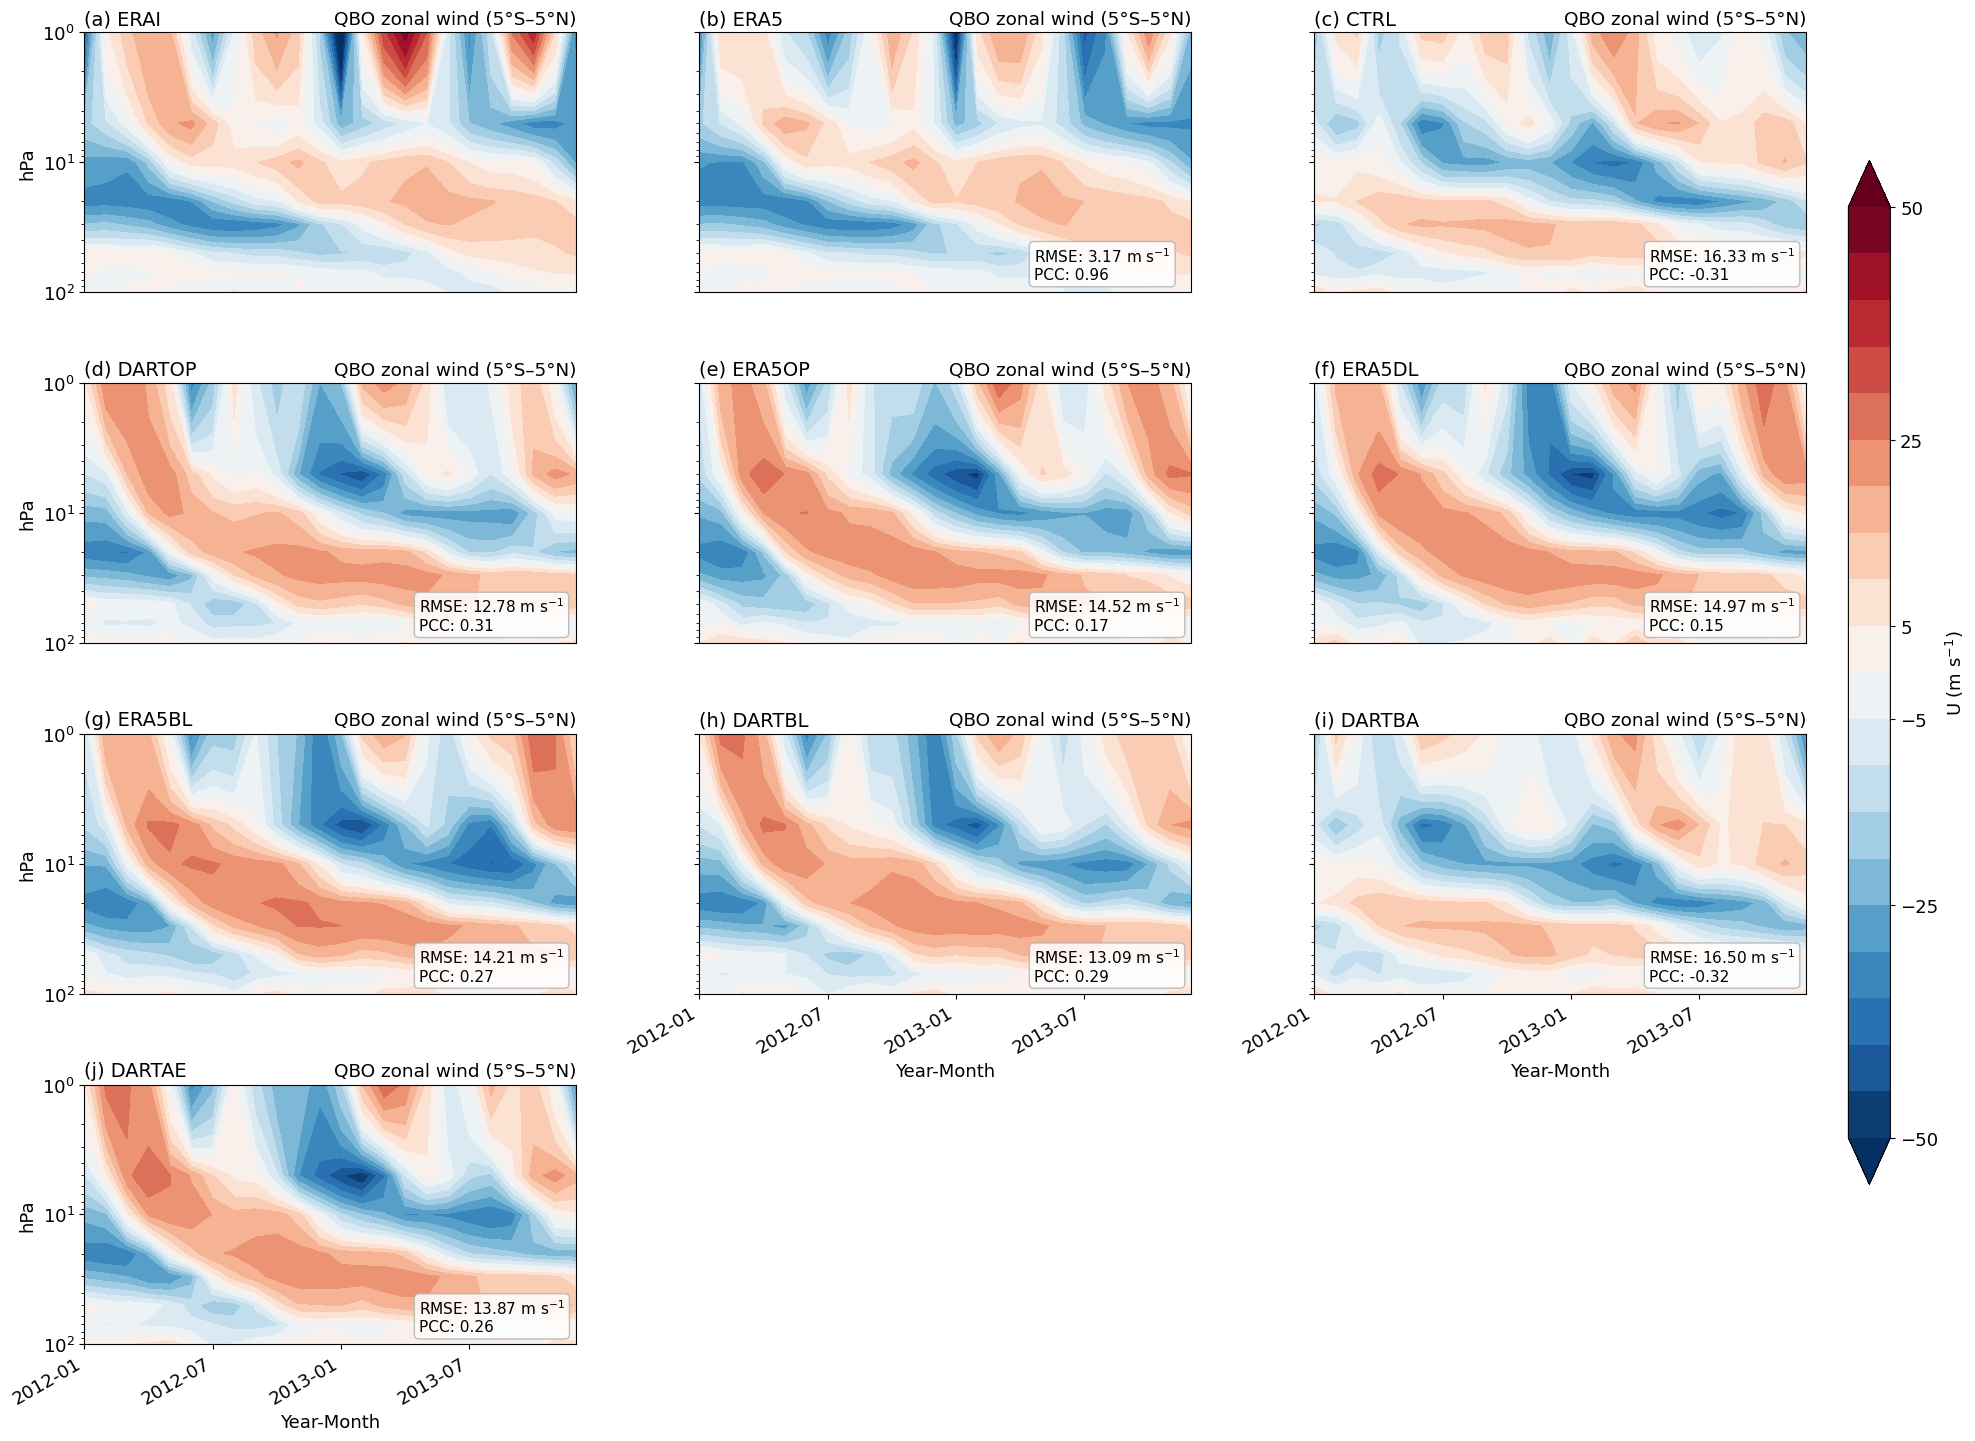

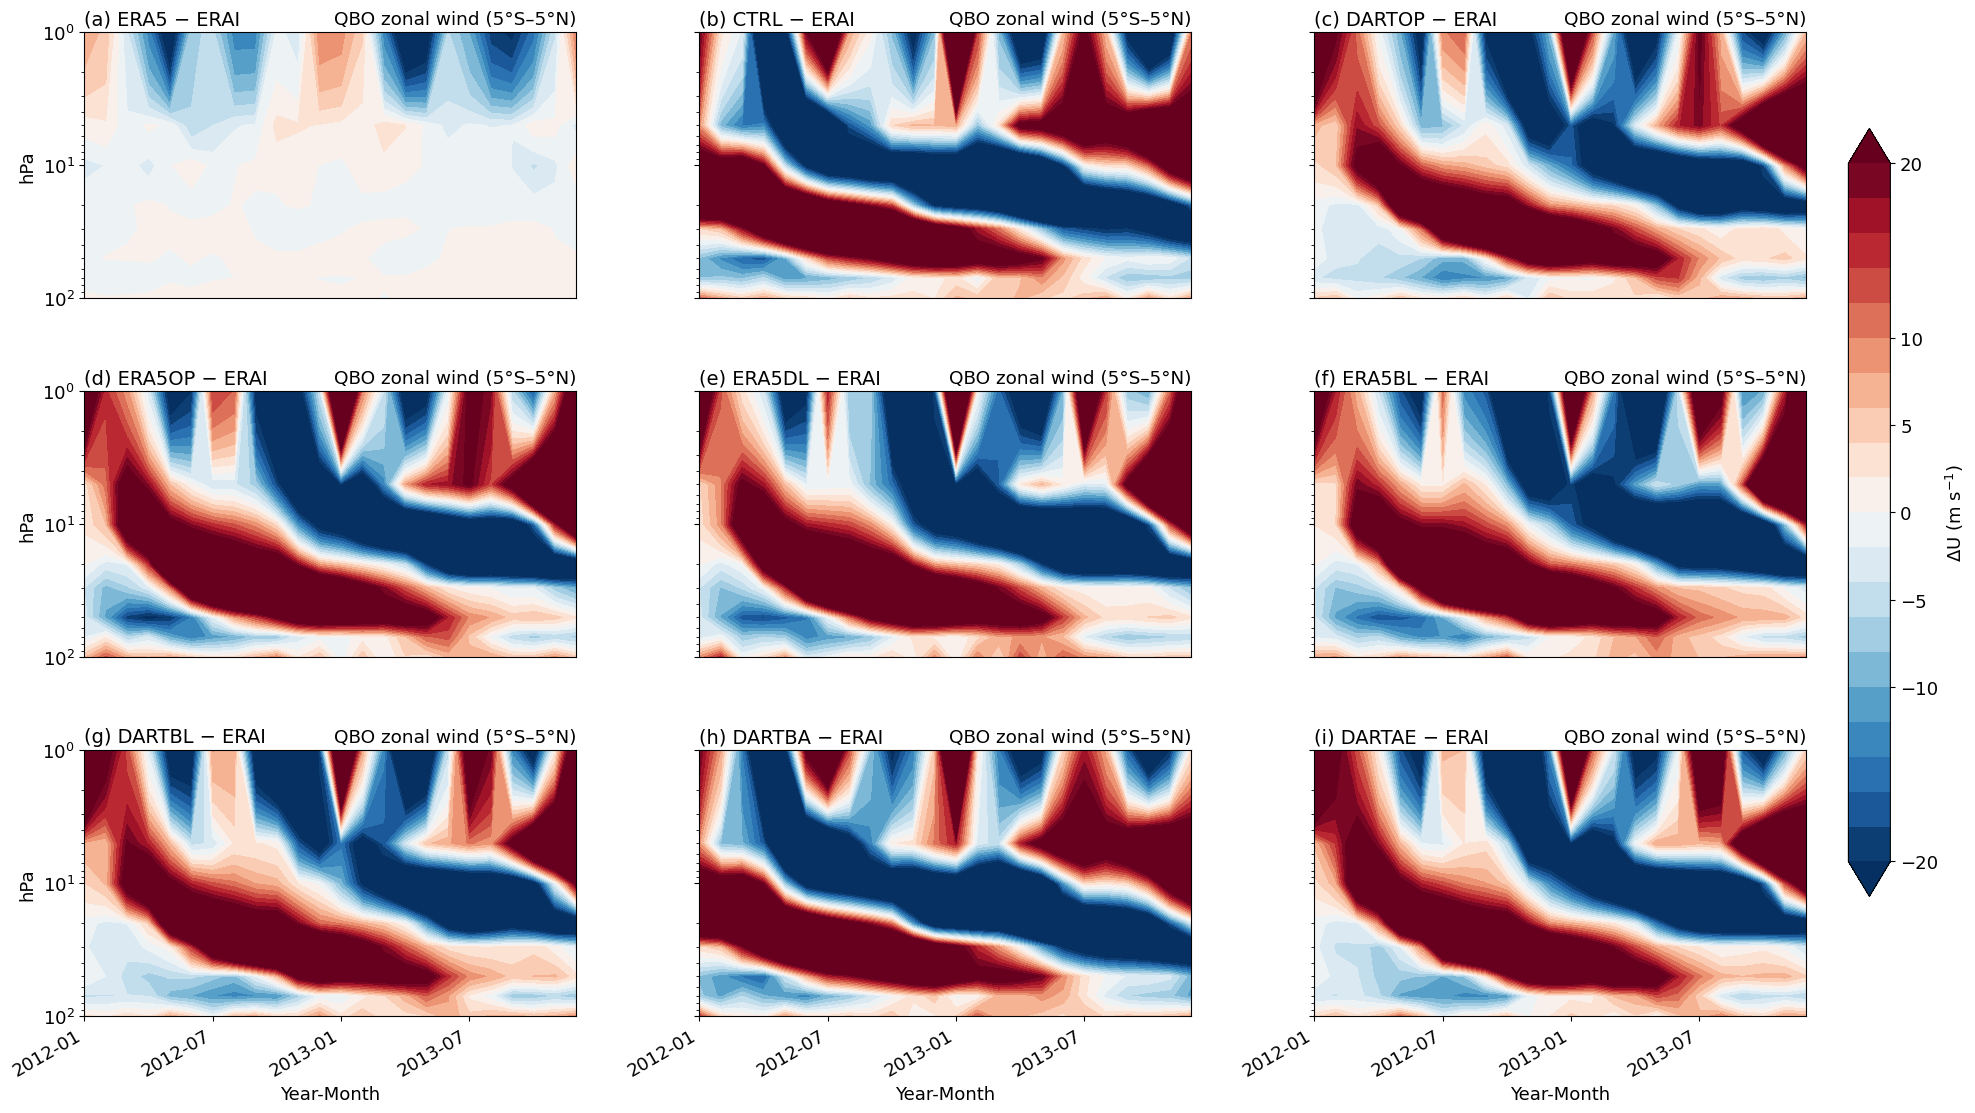

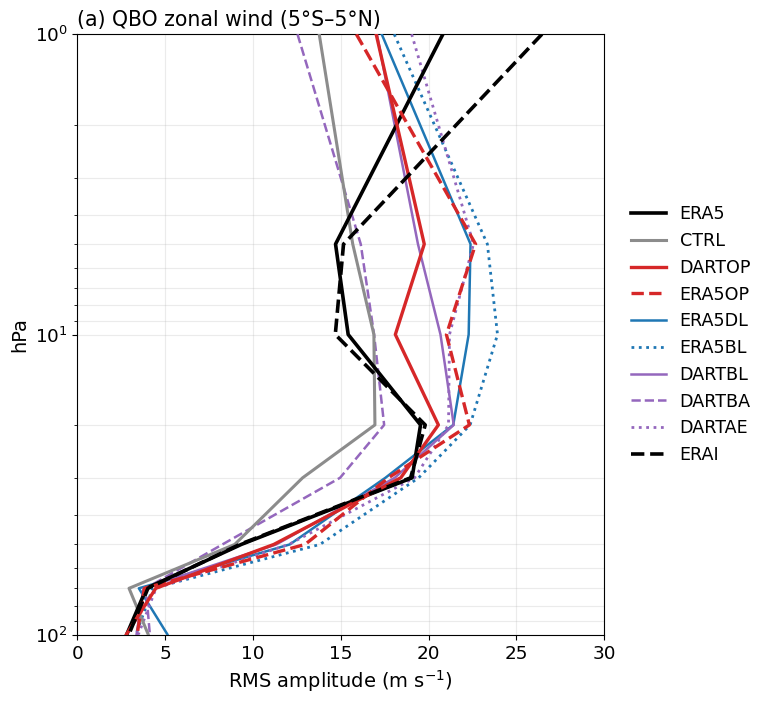

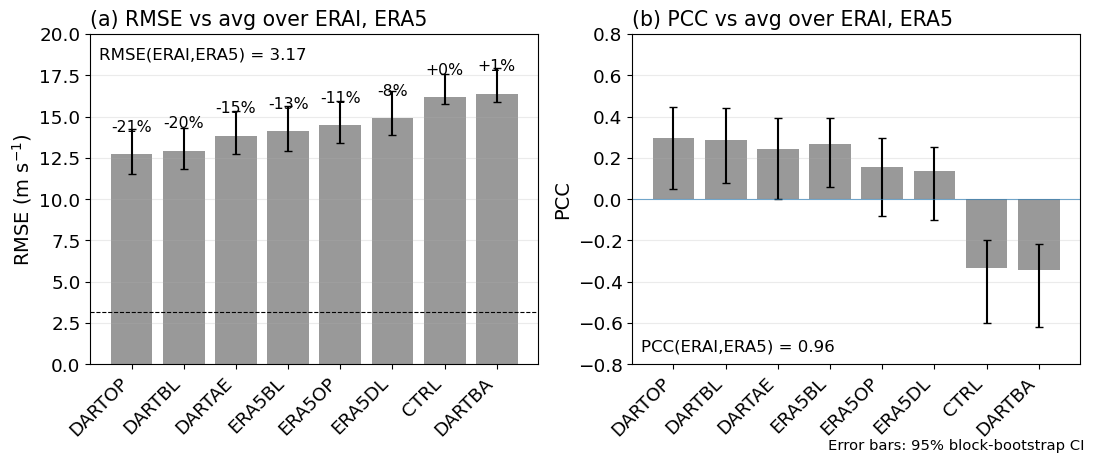

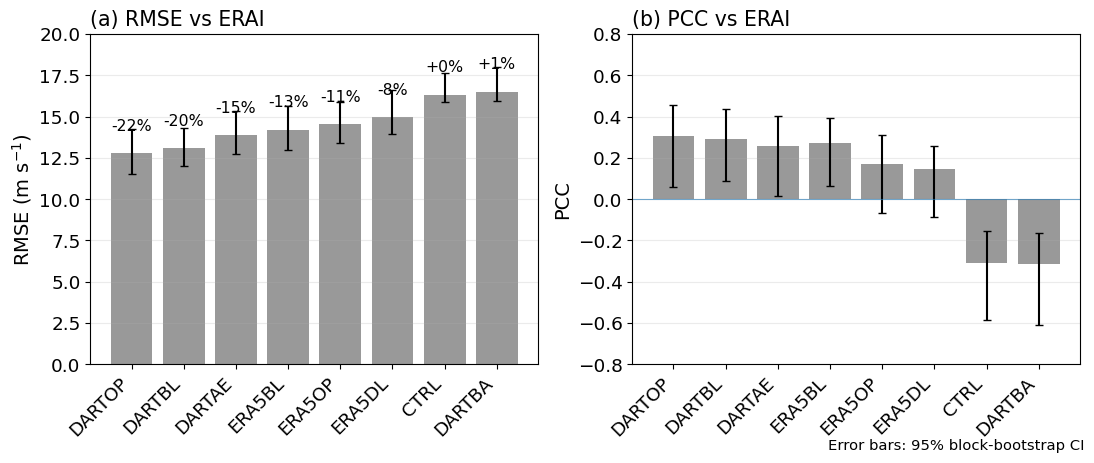

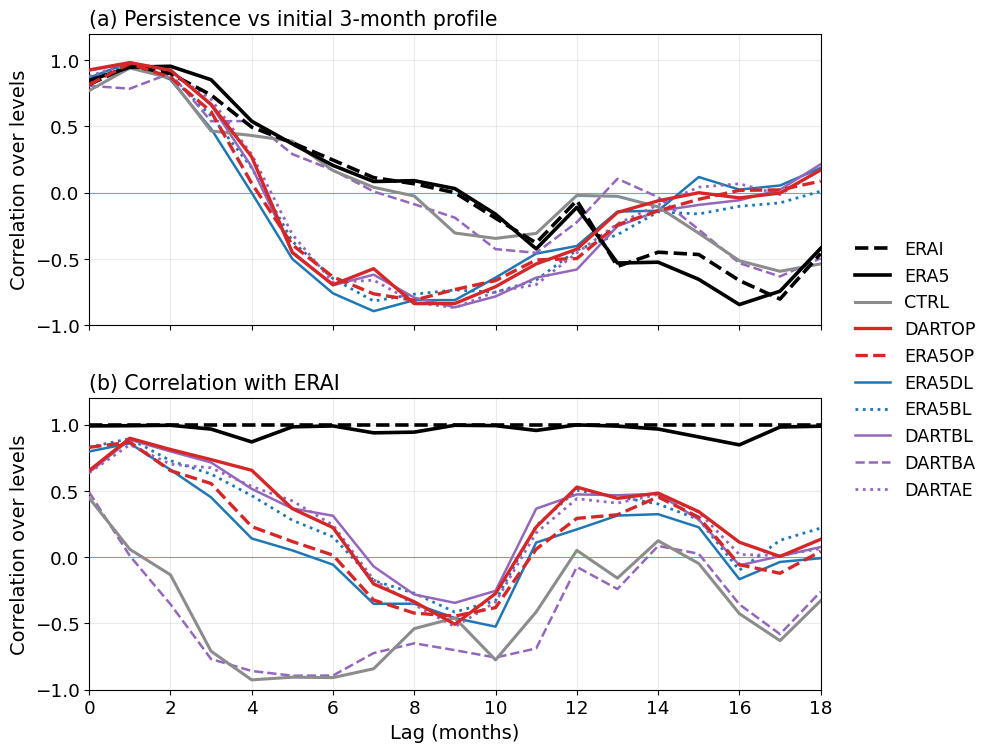

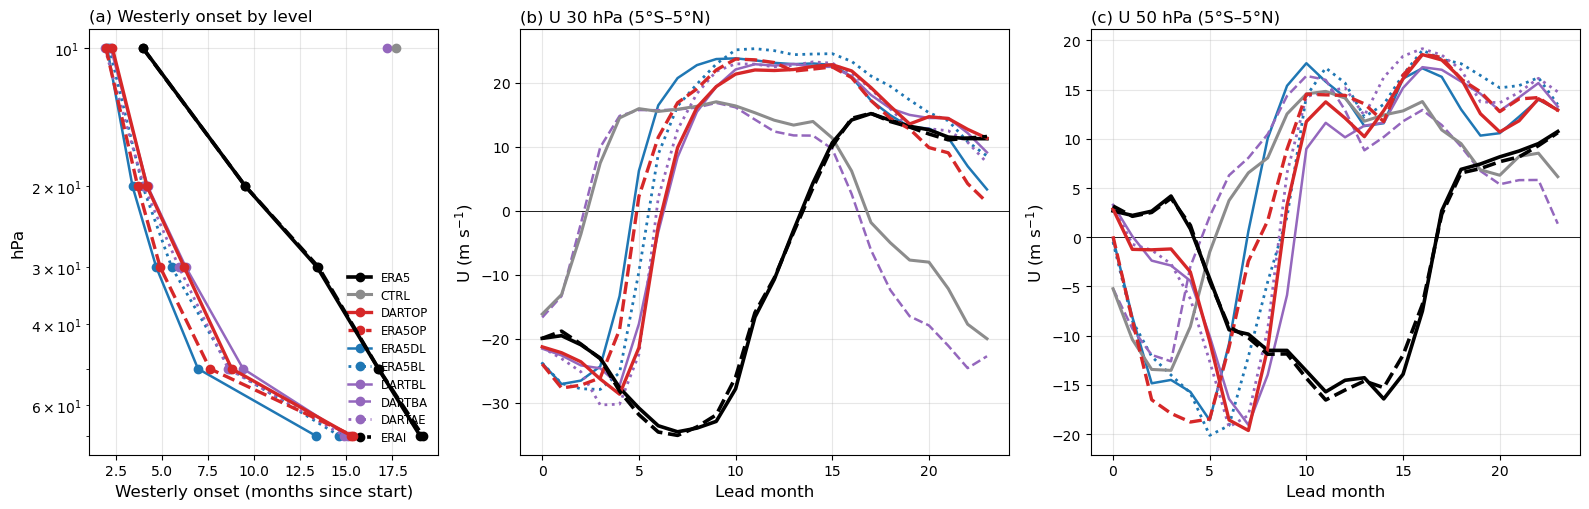

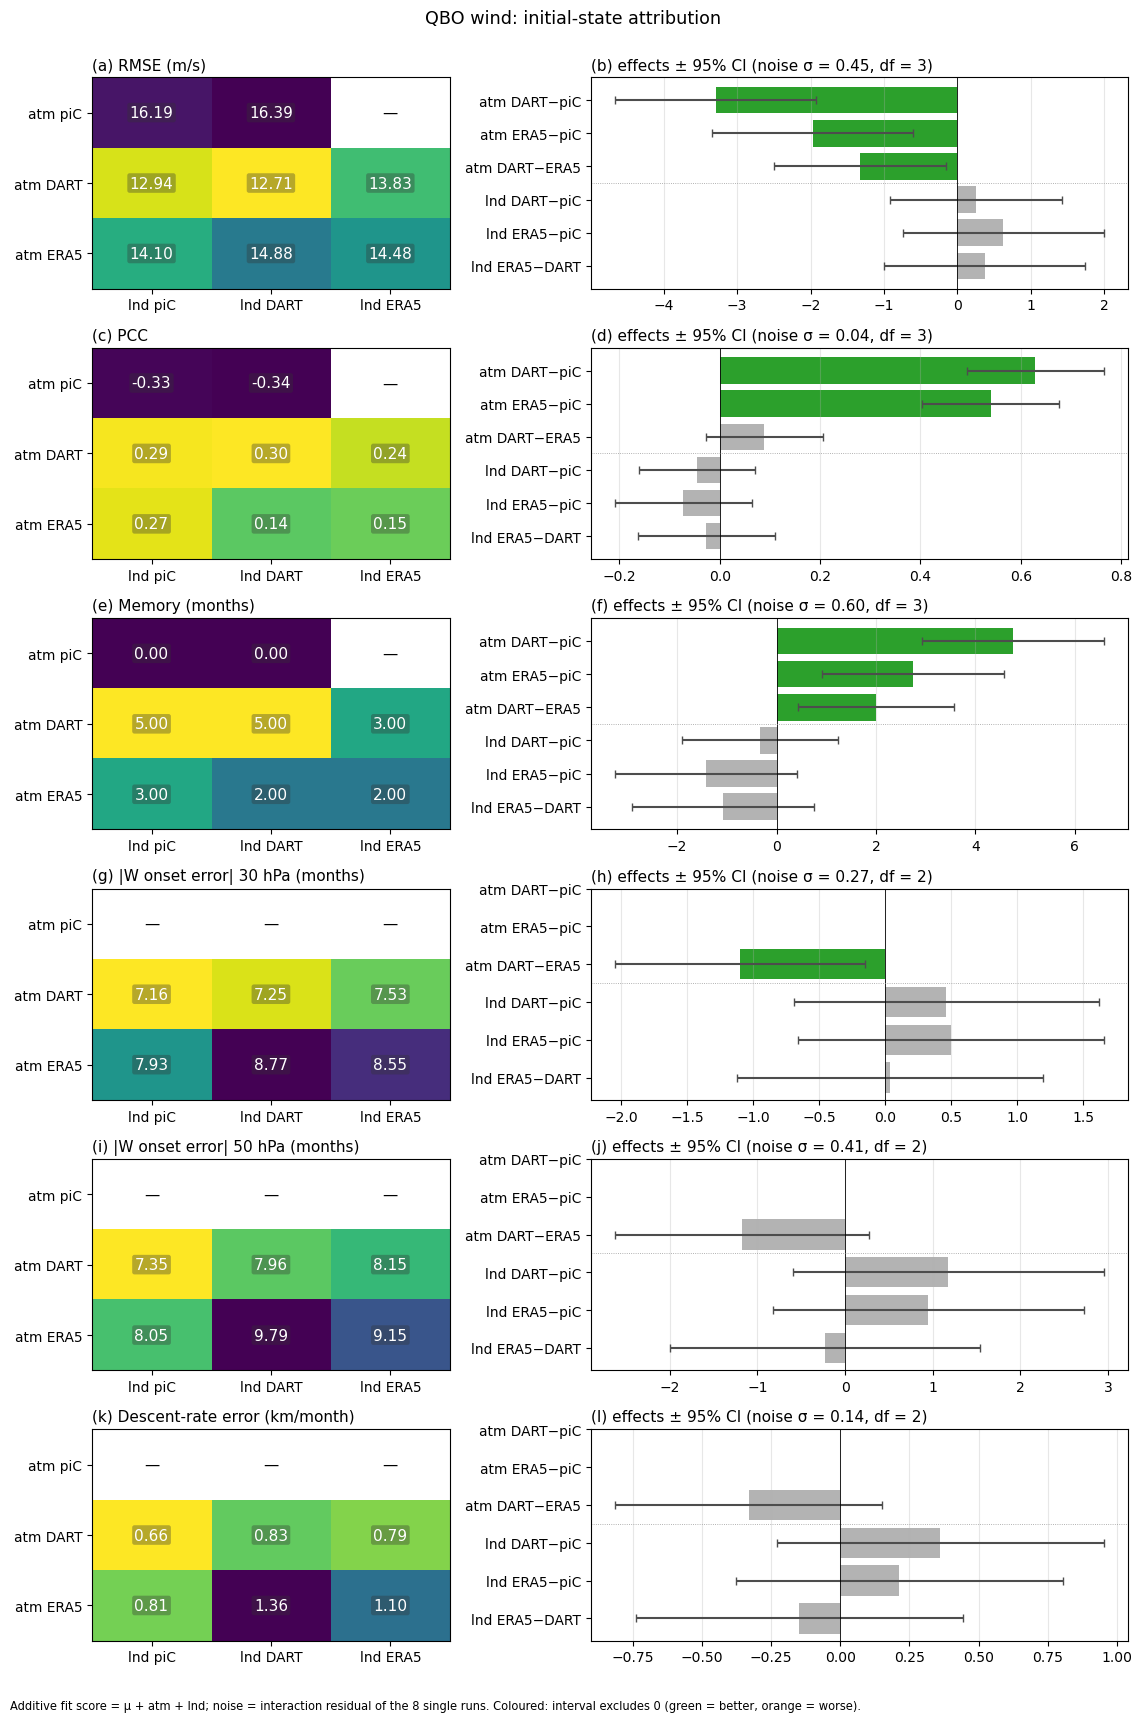

In [8]:
from util.hind_factorial import plot_factorial_scorecard
from util.qbo_plotting import plot_qbo_timing

sources = [OTHER_REANALYSIS, *EXPERIMENTS]
save(plotter.plot_timepressure(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ua_sections_vs_{REFERENCE}.png")
save(plotter.plot_timepressure_diffs(REFERENCE, sources, font_scale=FONT_SCALE, w_per_col=7, h_per_row=4),
     f"qbo_ua_diffs_vs_{REFERENCE}.png")
save(plotter.plot_amplitude(REFERENCE, sources, xlim=(0, 30), font_scale=FONT_SCALE), "qbo_ua_amplitude_rms.png")
for refs in (list(REFERENCES), [REFERENCE]):
    tag = "_".join(refs)
    fig, _ = plotter.plot_skill_bars(refs, EXPERIMENTS, table=skill[tag], font_scale=FONT_SCALE)
    save(fig, f"qbo_ua_skillbars_{tag}.png")
save(plotter.plot_lagcorr_persistence(REFERENCE, sources, font_scale=FONT_SCALE),
     f"qbo_ua_persistence_vs_{REFERENCE}.png")
save(plot_qbo_timing(data_dir, REFERENCE, sources, timing), "qbo_ua_timing.png")
save(plot_factorial_scorecard(scores, effects, labels={k: v[0] for k, v in SCORE_COLUMNS.items()},
                              higher_is_better={k: v[1] for k, v in SCORE_COLUMNS.items()},
                              title="QBO wind: initial-state attribution"), "qbo_ua_factorial.png")